# Generador de geometría y datos para el modelo 2D (HEC-RAS) — versión corregida
## Trabajo 01 · Estructura N.º 8 · Bifurcación de canales · Fase IV (preparación)

**Curso:** Flujo en superficie libre — UNSCH, Unidad de Posgrado

Este cuaderno reemplaza al generador anterior (`Generador de topografía y datos (JSON)`). Genera todo lo necesario para construir el modelo 2D **con los mismos datos de las Fases I a III** (`datos_entrada.json`: $Q_0=12$ m³/s, $b_0=4$ m, ramales de 3 y 2 m, tirantes de control fijos). La referencia 1D que se comparará con el 2D se calcula aquí con el **código de la Formulación II sin cambios**.

### Correcciones respecto del generador anterior

| # | Problema del original | Corrección | Prueba que lo detecta |
|---|---|---|---|
| 1 | Breaklines con el orden de vértices roto (una recta espuria cruzaba el dominio) y sin la divisoria | Se derivan del contorno del polígono mojado, ordenadas, e incluyen la divisoria | T3 |
| 2 | El canal principal terminaba en x = 0 y los ramales arrancaban perpendiculares a su eje: estrechamiento de 1.50 a 1.05 m en 1 cm | La geometría se define como polígono con la esquina aguas arriba del ramal (E) como único punto de quiebre; el ancho es continuo | T2 |
| 3 | El punto de prueba "banco" (10, 6) estaba dentro del cauce | Los puntos de prueba se calculan a partir de la geometría y se verifican contra la función analítica | T4 |
| 4 | Terreno `.xyz` (no verificado como entrada de RAS Mapper) | GeoTIFF con CRS, más shapefiles de área 2D, breaklines, BC, líneas de perfil y regiones de Manning | T5, T6 |
| 5 | Paso de tiempo fijo de 2 s con celdas de 0.1 m (Courant ≈ 90) | Se calculan Courant y paso de tiempo para cada malla | tabla de mallas |
| 6 | Control crítico dependiente de Q y Froude ≈ 0.8 en la unión | Controles de **tirante fijo**, como en las Fases I a III; Fr en la unión ≈ 0.5 | referencia 1D |

**Los datos son hipotéticos.** El sistema de coordenadas (UTM 18 S, EPSG:32718) y el origen se eligieron solo para que HEC-RAS tenga una proyección válida; **no corresponden a un sitio real**.

### Hipótesis de geometría que el modelo 1D no tiene
El 1D no usa el ángulo de derivación. Aquí se fija **θ = 45°** (ramal 2 sale por la margen izquierda), y el ramal 1 continúa recto con su pared derecha alineada con la del canal principal. θ es un parámetro del generador (`THETA_DEG`) y es precisamente uno de los efectos que el 2D puede explorar y el 1D no.

## 1. Librerías y versiones

In [1]:
import sys, json, os, copy, subprocess
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

try:
    import rasterio, shapefile, shapely, pyproj
except ImportError:                       # Colab: instalar una sola vez
    subprocess.run([sys.executable, "-m", "pip", "-q", "install", "rasterio", "pyshp", "shapely", "pyproj"], check=True)
    import rasterio, shapefile, shapely, pyproj

# Compatibilidad de 'affine': en algunas instalaciones affine 3.x falla con TypeError ("No '__dict__' attribute ... _astuple")
import affine as _affine
try:
    _ = _affine.Affine.translation(0, 0) * _affine.Affine.scale(1, -1)
except TypeError:
    subprocess.run([sys.executable, "-m", "pip", "-q", "install", "affine<3"], check=True)
    raise SystemExit("Se instaló affine<3 por incompatibilidad. Reinicia el kernel (Kernel > Restart) y ejecuta todo de nuevo.")
from shapely.geometry import Polygon, LineString, Point, box
from shapely.geometry.polygon import orient
from rasterio.features import rasterize
from rasterio.transform import from_origin

print('Python     :', sys.version.split()[0])
print('NumPy      :', np.__version__)
print('pandas     :', pd.__version__)
print('matplotlib :', matplotlib.__version__)
print('rasterio   :', rasterio.__version__)
print('pyshp      :', shapefile.__version__)
print('shapely    :', shapely.__version__)
print('pyproj     :', pyproj.__version__)
print('affine     :', _affine.__version__)

Python     : 3.10.4
NumPy      : 2.2.6
pandas     : 2.2.3
matplotlib : 3.10.3
rasterio   : 1.4.4
pyshp      : 3.1.6
shapely    : 2.1.2
pyproj     : 3.7.1
affine     : 2.4.0


## 2. Datos de las Fases I a III y referencia 1D

Se lee `datos_entrada.json` (el mismo de la Parte 1). Si el archivo no está en la carpeta, se crea con los valores de la Parte 1 y se avisa.

In [2]:
DATOS_DEFECTO = {
    "g": 9.81, "Q0": 12.0, "b0": 4.0, "z0": 100.0, "phi": 0.35,
    "ramal1": {"b": 3.0, "n": 0.015, "L": 200.0, "zJ": 100.0, "S": 0.0008, "yd": 1.60, "K": 0.20},
    "ramal2": {"b": 2.0, "n": 0.018, "L": 150.0, "zJ": 100.0, "S": 0.0010, "yd": 1.40, "K": 0.20}}
if not os.path.exists("datos_entrada.json"):
    with open("datos_entrada.json", "w", encoding="utf-8") as f:
        json.dump(DATOS_DEFECTO, f, indent=2)
    print("AVISO: no se encontró datos_entrada.json; se creó con los datos de la Parte 1.")
with open("datos_entrada.json", encoding="utf-8") as f:
    datos = json.load(f)
print("Datos leídos de datos_entrada.json")

AVISO: no se encontró datos_entrada.json; se creó con los datos de la Parte 1.
Datos leídos de datos_entrada.json


### 2.1 Código de la Formulación II (sin cambios)

In [3]:
def pendiente_friccion(n, Q, b, y):
    """Sf de Manning en canal rectangular y sus derivadas parciales (Q, y, b)."""
    A = b*y
    P = b + 2*y
    Sf = n**2 * Q**2 * P**(4/3) / A**(10/3)
    dSf_dQ = 2*Sf/Q
    dSf_dy = Sf*(8/(3*P) - 10/(3*y))
    dSf_db = Sf*(4/(3*P) - 10/(3*b))
    return Sf, dSf_dQ, dSf_dy, dSf_db


def ramal(Q, b, HJ, p, g):
    """Ecuacion de energia G de un ramal (union -> control) y sus derivadas.
    Devuelve (G, dG/dQ, dG/dHJ, dG/db) o None si el estado es inadmisible."""
    n, L, zJ, S, yd, K = p["n"], p["L"], p["zJ"], p["S"], p["yd"], p["K"]
    zd = zJ - S*L                     # cota de fondo en la seccion de control
    yJ = HJ - zJ                      # tirante en la union
    if Q <= 0 or b <= 0 or yJ <= 0:
        return None
    AJ, Ad = b*yJ, b*yd
    SfJ, dSfJ_dQ, dSfJ_dy, dSfJ_db = pendiente_friccion(n, Q, b, yJ)
    Sfd, dSfd_dQ, _,        dSfd_db = pendiente_friccion(n, Q, b, yd)

    G = (HJ + (1-K)*Q**2/(2*g*AJ**2)
         - (zd + yd) - Q**2/(2*g*Ad**2)
         - 0.5*L*(SfJ + Sfd))

    dG_dQ  = (1-K)*Q/(g*AJ**2) - Q/(g*Ad**2) - 0.5*L*(dSfJ_dQ + dSfd_dQ)
    dG_dH  = 1 - (1-K)*Q**2/(g*b**2*yJ**3) - 0.5*L*dSfJ_dy
    dG_db  = (-(1-K)*Q**2/(g*b**3*yJ**2) + Q**2/(g*b**3*yd**2)
              - 0.5*L*(dSfJ_db + dSfd_db))
    return G, dG_dQ, dG_dH, dG_db

In [4]:
def crear_sistema(d, modo, b2_fijo=None):
    """Devuelve (F, J) para el modo 'analisis' (3x3) o 'diseno' (4x4)."""
    g, Q0, phi = d["g"], d["Q0"], d["phi"]
    p1, p2 = d["ramal1"], d["ramal2"]
    yref = p1["yd"]                                   # m, escala de las ecuaciones de energia
    b2_dato = p2["b"] if b2_fijo is None else b2_fijo

    def F(x):
        Q1, Q2, HJ = x[0], x[1], x[2]
        b2 = x[3] if modo == "diseno" else b2_dato
        r1 = ramal(Q1, p1["b"], HJ, p1, g)
        r2 = ramal(Q2, b2,      HJ, p2, g)
        if r1 is None or r2 is None:
            return None
        f = [(Q0 - Q1 - Q2)/Q0, r1[0]/yref, r2[0]/yref]
        if modo == "diseno":
            f.append((Q2 - phi*Q0)/Q0)
        return np.array(f)

    def J(x):
        Q1, Q2, HJ = x[0], x[1], x[2]
        b2 = x[3] if modo == "diseno" else b2_dato
        r1 = ramal(Q1, p1["b"], HJ, p1, g)
        r2 = ramal(Q2, b2,      HJ, p2, g)
        if modo == "analisis":
            return np.array([[-1/Q0, -1/Q0, 0.0],
                             [r1[1]/yref, 0.0, r1[2]/yref],
                             [0.0, r2[1]/yref, r2[2]/yref]])
        return np.array([[-1/Q0, -1/Q0, 0.0, 0.0],
                         [r1[1]/yref, 0.0, r1[2]/yref, 0.0],
                         [0.0, r2[1]/yref, r2[2]/yref, r2[3]/yref],
                         [0.0, 1/Q0, 0.0, 0.0]])
    return F, J

In [5]:
def newton_amortiguado(F, J, x0, tol=1e-12, max_iter=50, lam_min=1e-4):
    """Newton-Raphson con retroceso. Devuelve (x, tabla de iteraciones, convergio)."""
    x = np.array(x0, dtype=float)
    F0 = F(x)
    if F0 is None:
        raise ValueError("El valor inicial es fisicamente inadmisible.")
    filas, lam = [], np.nan
    for k in range(max_iter + 1):
        Fx = F(x)
        normF = np.max(np.abs(Fx))
        filas.append({"Iteración": k, **{f"x{j+1}": x[j] for j in range(len(x))},
                      "‖F‖∞": normF, "λ": lam})
        if normF < tol:
            return x, pd.DataFrame(filas), True
        dx = np.linalg.solve(J(x), -Fx)              # J dx = -F
        lam = 1.0
        while lam >= lam_min:
            x_nuevo = x + lam*dx
            F_nuevo = F(x_nuevo)
            if F_nuevo is not None and np.max(np.abs(F_nuevo)) < (1 - 1e-4*lam)*normF:
                break
            lam /= 2
        else:
            return x, pd.DataFrame(filas), False     # sin paso admisible
        x = x_nuevo
    return x, pd.DataFrame(filas), False


def valor_inicial(d, b2=None):
    """Reparto por conductancia y nivel inicial en la union."""
    p1, p2 = d["ramal1"], d["ramal2"]
    b2 = p2["b"] if b2 is None else b2
    def K(b, y, n):
        A, P = b*y, b + 2*y
        return A*(A/P)**(2/3)/n
    K1, K2 = K(p1["b"], p1["yd"], p1["n"]), K(b2, p2["yd"], p2["n"])
    Q1 = d["Q0"]*K1/(K1 + K2)
    HJ = max(p1["zJ"] + p1["yd"], p2["zJ"] + p2["yd"]) + 0.05
    return Q1, d["Q0"] - Q1, HJ

### 2.2 Solución 1D de referencia

Modo A con $b_2$ dado. El tirante en el inicio de cada ramal es $y_J-K_iV_i^2/2g$ porque la energía de la Formulación II descuenta la pérdida local $K_i$ entre la unión y el ramal.

In [6]:
F_a, J_a = crear_sistema(datos, "analisis")
Q1_0, Q2_0, HJ_0 = valor_inicial(datos)
x1d, _, ok1d = newton_amortiguado(F_a, J_a, [Q1_0, Q2_0, HJ_0])
assert ok1d, "Newton no convergió"
Q1, Q2, HJ = x1d
g = datos["g"]
yJ = HJ - datos["z0"]
filas = []
for nombre, Q, b in (("Canal principal", datos["Q0"], datos["b0"]),
                     ("Ramal 1", Q1, datos["ramal1"]["b"]), ("Ramal 2", Q2, datos["ramal2"]["b"])):
    V = Q/(b*yJ)
    filas.append({"Tramo": nombre, "Q [m³/s]": Q, "b [m]": b, "y en la unión [m]": yJ, "V [m/s]": V, "Froude": V/np.sqrt(g*yJ)})
ref1d = pd.DataFrame(filas)
display(ref1d.style.format(precision=4).hide(axis="index"))
print(f"H_J = {HJ:.5f} m   φ = Q2/Q0 = {Q2/datos['Q0']:.5f}   (Q1 = {Q1:.5f}, Q2 = {Q2:.5f} m³/s)")
assert (ref1d["Froude"] < 1).all(), "Referencia 1D supercrítica"

Tramo,Q [m³/s],b [m],y en la unión [m],V [m/s],Froude
Canal principal,12.0000,4.0000,1.5937,1.8824,0.4761
Ramal 1,6.9405,3.0000,1.5937,1.4517,0.3671
Ramal 2,5.0595,2.0000,1.5937,1.5874,0.4015


H_J = 101.59368 m   φ = Q2/Q0 = 0.42163   (Q1 = 6.94049, Q2 = 5.05951 m³/s)


## 3. Parámetros del modelo 2D

Los que **no** vienen de las Fases I a III son hipótesis del generador y están marcados.

In [7]:
# --- Hipotesis del generador (no vienen del modelo 1D) ---
THETA_DEG = 45.0        # angulo de derivacion del ramal 2 respecto del eje del canal principal
N_CANAL_A = 0.015       # Manning del canal principal (el 1D no lo usa; se toma igual al del ramal 1)
LONG_A    = 25.0        # m, longitud del canal principal aguas arriba de la union (desarrollo del flujo)
Z_BANCO   = 102.5       # m, cota de bancos (mayor que el nivel maximo esperado, ~101.6 m)
MARGEN    = 0.5         # m, margen de celdas de banco alrededor del cauce en el poligono del area 2D
DX_RASTER = 0.10        # m, resolucion del GeoTIFF de terreno
ORIGEN    = (500000.0, 8500000.0)   # (X, Y) UTM 18S ficticios del centro de la union
EPSG      = 32718
T_RAMPA, T_TOTAL, Q_INICIAL = 600.0, 3600.0, 0.5   # s, s, m3/s

th = np.radians(THETA_DEG)
b0, b1, b2 = datos["b0"], datos["ramal1"]["b"], datos["ramal2"]["b"]
L1, L2 = datos["ramal1"]["L"], datos["ramal2"]["L"]
z0, zJ1, zJ2 = datos["z0"], datos["ramal1"]["zJ"], datos["ramal2"]["zJ"]
S1, S2 = datos["ramal1"]["S"], datos["ramal2"]["S"]
yd1, yd2 = datos["ramal1"]["yd"], datos["ramal2"]["yd"]
WSE_C1 = zJ1 - S1*L1 + yd1          # nivel impuesto al final del ramal 1
WSE_C2 = zJ2 - S2*L2 + yd2          # nivel impuesto al final del ramal 2
assert b1 <= b0, "El ramal 1 no puede ser mas ancho que el canal principal en este esquema"
print(f"θ = {THETA_DEG:.0f}°  |  niveles impuestos: ramal 1 = {WSE_C1:.3f} m, ramal 2 = {WSE_C2:.3f} m")

θ = 45°  |  niveles impuestos: ramal 1 = 101.440 m, ramal 2 = 101.250 m


## 4. Geometría como polígono

**Esquema (coordenadas locales, centro de la unión en el origen):**

* Canal principal: $x\in[-L_A,0]$, $|y|\le b_0/2$.
* Ramal 1 (continúa): $x\in[0,L_1]$, con su pared inferior alineada con la del canal principal, $y\in[-b_0/2,\,-b_0/2+b_1]$.
* Ramal 2 (deriva): franja de ancho $b_2$ con eje a ángulo $\theta$. Su pared **aguas arriba** arranca de la esquina **E** $=(0,\,b_0/2)$ y su pared **aguas abajo** termina en el vértice **C** (la esquina de la divisoria, intersección con la pared superior del ramal 1). En el modelo de Milne-Thomson, C es el punto de estancamiento y E es la esquina donde el flujo real se separa.

Como el contorno se define con **un solo punto de quiebre en E**, el ancho es continuo entre el canal principal y la abertura del ramal 2. El contorno del polígono es de donde se derivan después las breaklines, las líneas de condición de borde y el polígono del área 2D.

In [8]:
u = np.array([np.cos(th), np.sin(th)])            # direccion del eje del ramal 2
n_ = np.array([-np.sin(th), np.cos(th)])           # normal (hacia la margen izquierda del ramal 2)
E  = np.array([0.0, b0/2])                         # esquina aguas arriba del ramal 2
y1top = -b0/2 + b1                                 # pared superior del ramal 1
# vertice C: pared aguas abajo del ramal 2 (E + b2*(sin, -cos) + t*u) con y = y1top
t_C = (y1top - (E[1] - b2*np.cos(th)))/np.sin(th)
C = E + b2*np.array([np.sin(th), -np.cos(th)]) + t_C*u
assert C[0] > 0, "Con este theta la divisoria cae aguas arriba de x=0: ajustar la geometria"
P_up = E + L2*u                                    # fin de la pared aguas arriba del ramal 2
P_dn = P_up + b2*np.array([np.sin(th), -np.cos(th)])

V_IN_INF = np.array([-LONG_A, -b0/2]); V_IN_SUP = np.array([-LONG_A, b0/2])
V_R1_INF = np.array([L1, -b0/2]);      V_R1_SUP = np.array([L1, y1top])

vertices = [V_IN_INF, V_R1_INF, V_R1_SUP, C, P_dn, P_up, E, V_IN_SUP]     # sentido antihorario
mojado = Polygon(vertices)
assert mojado.is_valid and mojado.is_simple, "Poligono mojado invalido"
area_cauce = mojado.area
print("Vértices del cauce (x, y):")
for nombre, v in zip(["inicio-inf", "fin ramal 1 inf", "fin ramal 1 sup", "C (divisoria)", "fin ramal 2 dn", "fin ramal 2 up", "E (esquina up)", "inicio-sup"], vertices):
    print(f"   {nombre:16s} ({v[0]:9.3f}, {v[1]:9.3f})")
print(f"Área del cauce: {area_cauce:.1f} m²   perímetro: {mojado.length:.1f} m")

Vértices del cauce (x, y):
   inicio-inf       (  -25.000,    -2.000)
   fin ramal 1 inf  (  200.000,    -2.000)
   fin ramal 1 sup  (  200.000,     1.000)
   C (divisoria)    (    1.828,     1.000)
   fin ramal 2 dn   (  107.480,   106.652)
   fin ramal 2 up   (  106.066,   108.066)
   E (esquina up)   (    0.000,     2.000)
   inicio-sup       (  -25.000,     2.000)
Área del cauce: 1000.3 m²   perímetro: 756.6 m


### 4.1 Elementos para HEC-RAS derivados del contorno

In [9]:
def s_coord(x, y):             # distancia a lo largo del eje del ramal 2 medida desde la perpendicular por E
    return (x - E[0])*u[0] + (y - E[1])*u[1]

# --- Breaklines (ordenadas, sobre las paredes) ---
breaklines = {
    "pared_inferior": [V_IN_INF, V_R1_INF],                    # canal principal + ramal 1 (margen derecha)
    "pared_superior": [V_IN_SUP, E, P_up],                     # canal principal + pared aguas arriba del ramal 2
    "pared_divisoria": [P_dn, C, V_R1_SUP],                    # pared aguas abajo del ramal 2 + pared superior del ramal 1
}
# --- Lineas de condicion de borde (sobre el borde del area 2D, cortando el cauce) ---
bc_lineas = {
    "BC_ENTRADA":   [V_IN_SUP, V_IN_INF],
    "BC_SALIDA_R1": [V_R1_SUP, V_R1_INF],
    "BC_SALIDA_R2": [P_dn, P_up],
}
# --- Poligono del area 2D: cauce + margen de bancos ---
area2d = mojado.buffer(MARGEN, join_style=2)          # esquinas en inglete
# --- Lineas de perfil y de caudal ---
eje2_0 = E - 0.5*b2*n_
perfiles = {
    "EJE_RAMAL1": [np.array([0.0, -b0/2 + b1/2]), np.array([L1, -b0/2 + b1/2])],
    "EJE_RAMAL2": [eje2_0, eje2_0 + L2*u],
}
def transversal(centro, direccion_perp, ancho):
    return [centro - 0.5*ancho*direccion_perp, centro + 0.5*ancho*direccion_perp]
lineas_Q = {
    "Q_CANAL_A": transversal(np.array([-10.0, 0.0]), np.array([0.0, 1.0]), b0),
    "Q_RAMAL1":  transversal(np.array([100.0, -b0/2 + b1/2]), np.array([0.0, 1.0]), b1),
    "Q_RAMAL2":  transversal(eje2_0 + 75.0*u, n_, b2),
}
puntos = {"NUDO": np.array([0.0, 0.0]), "ENT_R1": np.array([5.0, -b0/2 + b1/2]), "ENT_R2": eje2_0 + 5.0*u,
          "SALIDA_R1": np.array([L1 - 5.0, -b0/2 + b1/2]), "SALIDA_R2": eje2_0 + (L2 - 5.0)*u}

# --- Regiones de Manning ---
semiplano_R2 = box(-1e3, -1e3, 1e3, 1e3)   # se reemplaza por un semiplano rotado
s_C = s_coord(*C)
big = 1e3
sp = Polygon([E + n_*big + u*s_C - n_*0 , E - n_*big + u*s_C, E - n_*big + u*big, E + n_*big + u*big])
manning = {"n_ramal2": (datos["ramal2"]["n"], area2d.intersection(sp)),
           "n_base": (datos["ramal1"]["n"], area2d)}
print(f"Manning: ramal 2 (desde s = {s_C:.3f} m) n = {datos['ramal2']['n']}; resto n = {datos['ramal1']['n']} (canal principal: {N_CANAL_A})")
print(f"Área del polígono 2D (cauce + margen {MARGEN} m): {area2d.area:.1f} m²")

Manning: ramal 2 (desde s = 0.586 m) n = 0.018; resto n = 0.015 (canal principal: 0.015)
Área del polígono 2D (cauce + margen 0.5 m): 1379.4 m²


## 5. Terreno: función analítica y GeoTIFF

**Fondo.** Canal principal horizontal en $z_0$. Ramal 1: $z=z_{J,1}-S_1\,x$. Ramal 2: $z=z_{J,2}-S_2\,s$, con $s$ medida a lo largo de su eje desde la perpendicular por E (y $s\ge0$ en la zona de unión). Fuera del cauce, cota de banco constante.

**Muros.** El terreno tiene muros verticales de un píxel (0.10 m) en el contorno. El polígono del área 2D incluye un margen de bancos, y las breaklines siguen el contorno para que las caras de las celdas coincidan con las paredes.

In [10]:
def z_fondo(x, y):
    """Cota del fondo en puntos del cauce (arrays)."""
    x = np.asarray(x, float); y = np.asarray(y, float)
    z = np.full(np.broadcast(x, y).shape, z0)
    en_ramal = x > 0
    z1 = zJ1 - S1*x
    s = np.maximum(s_coord(x, y), 0.0)
    z2 = zJ2 - S2*s
    en_r1 = en_ramal & (y <= y1top)
    z = np.where(en_ramal, np.where(en_r1, z1, z2), z)
    return z

xmin, ymin, xmax, ymax = area2d.bounds
xmin, ymin = np.floor(xmin/DX_RASTER)*DX_RASTER - 1.0, np.floor(ymin/DX_RASTER)*DX_RASTER - 1.0
xmax, ymax = np.ceil(xmax/DX_RASTER)*DX_RASTER + 1.0, np.ceil(ymax/DX_RASTER)*DX_RASTER + 1.0
ncol, nfil = int(round((xmax - xmin)/DX_RASTER)), int(round((ymax - ymin)/DX_RASTER))
xc = xmin + (np.arange(ncol) + 0.5)*DX_RASTER
yc = ymax - (np.arange(nfil) + 0.5)*DX_RASTER           # fila 0 = norte
XC, YC = np.meshgrid(xc, yc)
tr_local = from_origin(xmin, ymax, DX_RASTER, DX_RASTER)
mascara_mojada = rasterize([(mojado, 1)], out_shape=(nfil, ncol), transform=tr_local, fill=0, dtype="uint8").astype(bool)
Z = np.where(mascara_mojada, z_fondo(XC, YC), Z_BANCO).astype("float32")
print(f"Raster {ncol} × {nfil} píxeles de {DX_RASTER} m  ({ncol*nfil*4/1e6:.1f} MB sin comprimir)")
print(f"Celdas mojadas: {mascara_mojada.sum():,}   área = {mascara_mojada.sum()*DX_RASTER**2:.1f} m²  (polígono: {area_cauce:.1f} m²)")

Raster 2280 × 1133 píxeles de 0.1 m  (10.3 MB sin comprimir)
Celdas mojadas: 99,740   área = 997.4 m²  (polígono: 1000.3 m²)


In [11]:
os.makedirs("salida_2d", exist_ok=True)
crs = pyproj.CRS.from_epsg(EPSG)
X0, Y0 = ORIGEN
tr_utm = from_origin(xmin + X0, ymax + Y0, DX_RASTER, DX_RASTER)
with rasterio.open("salida_2d/terreno_partidor.tif", "w", driver="GTiff", height=nfil, width=ncol, count=1,
                   dtype="float32", crs=f"EPSG:{EPSG}", transform=tr_utm, nodata=-9999.0, compress="deflate") as dst:
    dst.write(Z, 1)
print("terreno_partidor.tif escrito:", round(os.path.getsize("salida_2d/terreno_partidor.tif")/1e6, 2), "MB")

terreno_partidor.tif escrito: 0.22 MB


## 6. Shapefiles, CSV de referencia y condiciones de borde

In [12]:
def a_utm(p):
    return (float(p[0]) + X0, float(p[1]) + Y0)

wkt_esri = crs.to_wkt(version="WKT1_ESRI")
def escribir_lineas(nombre, dic):
    w = shapefile.Writer(f"salida_2d/{nombre}", shapeType=shapefile.POLYLINE)
    w.field("nombre", "C", size=24)
    for k, pts in dic.items():
        w.line([[a_utm(p) for p in pts]]); w.record(k)
    w.close(); open(f"salida_2d/{nombre}.prj", "w").write(wkt_esri)

def escribir_poligonos(nombre, lista):
    w = shapefile.Writer(f"salida_2d/{nombre}", shapeType=shapefile.POLYGON)
    w.field("nombre", "C", size=24); w.field("manning", "N", decimal=4)
    for k, n_man, geom in lista:
        geoms = list(geom.geoms) if geom.geom_type == "MultiPolygon" else [geom]
        for gm in geoms:
            gm = orient(gm, sign=-1.0)                      # exterior en sentido horario (norma del shapefile)
            w.poly([[a_utm(p) for p in gm.exterior.coords]]); w.record(k, n_man)
    w.close(); open(f"salida_2d/{nombre}.prj", "w").write(wkt_esri)

escribir_lineas("breaklines", breaklines)
escribir_lineas("bc_lines", bc_lineas)
escribir_lineas("perfiles_y_caudal", {**perfiles, **lineas_Q})
escribir_poligonos("area_2d", [("AREA_2D", 0.0, area2d)])
escribir_poligonos("manning_regiones", [("n_base", datos["ramal1"]["n"], manning["n_base"][1]),
                                         ("n_ramal2", datos["ramal2"]["n"], manning["n_ramal2"][1])])
w = shapefile.Writer("salida_2d/puntos_observacion", shapeType=shapefile.POINT)
w.field("nombre", "C", size=24)
for k, p in puntos.items():
    w.point(*a_utm(p)); w.record(k)
w.close(); open("salida_2d/puntos_observacion.prj", "w").write(wkt_esri)

# CSV de referencia (coordenadas locales y UTM)
filas = []
def agregar(grupo, dic):
    for k, pts in dic.items():
        pts = pts if isinstance(pts, list) else [pts]
        for i, p in enumerate(pts):
            filas.append({"grupo": grupo, "elemento": k, "vertice": i, "x_local_m": p[0], "y_local_m": p[1],
                          "x_utm_m": p[0] + X0, "y_utm_m": p[1] + Y0})
agregar("breakline", breaklines); agregar("bc", bc_lineas); agregar("perfil", perfiles)
agregar("linea_caudal", lineas_Q); agregar("punto", puntos)
ref_csv = pd.DataFrame(filas); ref_csv.to_csv("salida_2d/referencia_hecras.csv", index=False)

# Condiciones de borde
hid = pd.DataFrame({"t_s": [0.0, T_RAMPA, T_TOTAL], "Q_m3s": [Q_INICIAL, datos["Q0"], datos["Q0"]]})
hid.to_csv("salida_2d/bc_entrada_hydrograph.csv", index=False)
niveles = pd.DataFrame({"t_s": [0.0, T_TOTAL, 0.0, T_TOTAL], "borde": ["BC_SALIDA_R1"]*2 + ["BC_SALIDA_R2"]*2,
                        "WSE_m": [WSE_C1, WSE_C1, WSE_C2, WSE_C2]})
niveles.to_csv("salida_2d/bc_salida_stage.csv", index=False)
print(hid.to_string(index=False)); print(); print(niveles.to_string(index=False))
print("\nCondición inicial recomendada: nivel de agua uniforme =", round(max(WSE_C1, WSE_C2), 3), "m (cauce lleno de agua, bancos secos).")

   t_s  Q_m3s
   0.0    0.5
 600.0   12.0
3600.0   12.0

   t_s        borde  WSE_m
   0.0 BC_SALIDA_R1 101.44
3600.0 BC_SALIDA_R1 101.44
   0.0 BC_SALIDA_R2 101.25
3600.0 BC_SALIDA_R2 101.25

Condición inicial recomendada: nivel de agua uniforme = 101.44 m (cauce lleno de agua, bancos secos).


## 7. Perfiles 1D de referencia para la comparación

Perfil de superficie libre en cada ramal por integración de la ecuación de flujo gradualmente variado (Runge–Kutta de 4.º orden) desde el control hacia la unión, con los caudales de la Formulación II. Sirve para comparar con los perfiles del 2D.

**Un control de coherencia propio.** La Formulación II usa un solo paso con fricción promediada (limitación (a) de la Parte 1). Si el perfil integrado llega a la unión con un nivel distinto del que da el Newton, esa diferencia es el error del paso único.

In [13]:
def perfil_gvf(Q, b, n, S, zJ, yd, L, npasos=2000):
    ds = L/npasos
    def dydx(y):
        A, P = b*y, b + 2*y
        Sf = n**2*Q**2*P**(4/3)/A**(10/3)
        return (S - Sf)/(1 - Q**2*b/(g*A**3))
    d = np.linspace(L, 0.0, npasos + 1)
    y = np.empty(npasos + 1); y[0] = yd
    h = -ds
    for i in range(npasos):
        k1 = dydx(y[i]); k2 = dydx(y[i] + 0.5*h*k1); k3 = dydx(y[i] + 0.5*h*k2); k4 = dydx(y[i] + h*k3)
        y[i+1] = y[i] + h*(k1 + 2*k2 + 2*k3 + k4)/6
    d, y = d[::-1], y[::-1]
    return d, zJ - S*d + y, y

filas_ctrl = []
for nombre, Q, r in (("ramal1", Q1, datos["ramal1"]), ("ramal2", Q2, datos["ramal2"])):
    d_, wse_, y_ = perfil_gvf(Q, r["b"], r["n"], r["S"], r["zJ"], r["yd"], r["L"])
    pd.DataFrame({"d_m": d_, "WSE_m": wse_, "y_m": y_}).to_csv(f"salida_2d/perfil_1d_{nombre}.csv", index=False)
    V = Q/(r["b"]*yJ)
    wse_dentro_newton = HJ - r["K"]*V**2/(2*g)             # nivel justo dentro del ramal segun la Formulacion II
    filas_ctrl.append({"Ramal": nombre, "WSE integrado en d=0 [m]": wse_[0], "WSE Newton (H_J − K·V²/2g) [m]": wse_dentro_newton,
                       "Diferencia [mm]": 1000*(wse_[0] - wse_dentro_newton)})
ctrl = pd.DataFrame(filas_ctrl)
display(ctrl.style.format({"WSE integrado en d=0 [m]": "{:.4f}", "WSE Newton (H_J − K·V²/2g) [m]": "{:.4f}", "Diferencia [mm]": "{:+.1f}"}).hide(axis="index"))

Ramal,WSE integrado en d=0 [m],WSE Newton (H_J − K·V²/2g) [m],Diferencia [mm]
ramal1,101.5718,101.5722,-0.4
ramal2,101.5618,101.5680,-6.2


### 7.1 Referencia 1D con integración por tramos (para aislar el error del paso único)

El error de 6 mm del ramal 2 (más largo y con más fricción) afecta el reparto. Para saber cuánto, se **resuelve de nuevo el reparto usando el perfil integrado** en cada ramal en lugar de la energía de un solo paso: se busca $Q_1$ tal que el nivel de unión que resulta de cada ramal, $H_J=\text{WSE}(d{=}0)+K\,V_J^2/2g$, coincida. (Bisección propia; la pérdida local se trata igual que en la Formulación II.)

In [14]:
def nivel_union_integrado(Q, r, n_iter=60):
    _, wse, _ = perfil_gvf(Q, r["b"], r["n"], r["S"], r["zJ"], r["yd"], r["L"], npasos=500)
    H = wse[0]
    for _ in range(n_iter):                          # V_J usa el tirante en la union, y_J = H - z
        H = wse[0] + r["K"]*(Q/(r["b"]*(H - datos["z0"])))**2/(2*g)
    return H

lo, hi = 0.5, datos["Q0"] - 0.5
for _ in range(60):
    mid = 0.5*(lo + hi)
    f = nivel_union_integrado(mid, datos["ramal1"]) - nivel_union_integrado(datos["Q0"] - mid, datos["ramal2"])
    if f < 0: lo = mid
    else: hi = mid
Q1_int = 0.5*(lo + hi); Q2_int = datos["Q0"] - Q1_int
H_int = nivel_union_integrado(Q1_int, datos["ramal1"])
phi_1paso, phi_int = Q2/datos["Q0"], Q2_int/datos["Q0"]
print(f"Un solo paso (Formulación II) : Q1 = {Q1:.4f}  Q2 = {Q2:.4f}  φ = {phi_1paso:.4f}   H_J = {HJ:.4f} m")
print(f"Perfil integrado (RK4)        : Q1 = {Q1_int:.4f}  Q2 = {Q2_int:.4f}  φ = {phi_int:.4f}   H_J = {H_int:.4f} m")
print(f"Diferencia de φ por el paso único: {phi_1paso - phi_int:+.4f}  ({100*(phi_1paso/phi_int - 1):+.2f} % relativo)")

Un solo paso (Formulación II) : Q1 = 6.9405  Q2 = 5.0595  φ = 0.4216   H_J = 101.5937 m
Perfil integrado (RK4)        : Q1 = 6.9061  Q2 = 5.0939  φ = 0.4245   H_J = 101.5918 m
Diferencia de φ por el paso único: -0.0029  (-0.67 % relativo)


## 8. Pruebas del generador

Los criterios se fijaron antes de ejecutar. T2 y T3 se aplican también al **generador original** (reimplementado abajo con sus parámetros) para comprobar que esas pruebas realmente detectan los defectos que se corrigieron.

In [15]:
resultados = []
def registrar(nombre, obtenido, criterio, ok):
    resultados.append({"Prueba": nombre, "Obtenido": obtenido, "Criterio": criterio, "¿Cumple?": bool(ok)})

# T1: poligono valido; area del raster vs poligono
err_area = abs(mascara_mojada.sum()*DX_RASTER**2/area_cauce - 1)
registrar("T1 Polígono válido y área del raster = área del polígono", f"{100*err_area:.3f} %", "≤ 0.5 %",
          mojado.is_valid and mojado.is_simple and err_area <= 0.005)

# T2: continuidad del ancho mojado en la union (sin escalones)
def ancho_columnas(funcion_mojada, xs, ys):
    return np.array([funcion_mojada(x, ys).sum()*(ys[1] - ys[0]) for x in xs])
xs_t = np.arange(-2.0, 4.0, 0.05); ys_t = np.arange(-6.0, 6.0, 0.01)
def mojada_nueva(x, ys):
    return np.array([mojado.covers(Point(x, yy)) for yy in ys])
from shapely import contains_xy
W_nuevo = np.array([ (contains_xy(mojado, np.full_like(ys_t, x), ys_t)).sum()*0.01 for x in xs_t])
salto_nuevo = np.abs(np.diff(W_nuevo)).max()

# generador ORIGINAL (geometria de la version anterior, con sus propios parametros)
RAM_O = {"b": dict(b=1.00, S=0.002, ang=+30.0), "c": dict(b=0.80, S=0.0035, ang=-30.0)}
def elevacion_original(x, y):
    if x <= 0.0 and abs(y) <= 0.75: return 0.0
    zs = []
    for k, ext in (("b", 31.5), ("c", 26.5)):
        a = np.radians(RAM_O[k]["ang"]); uu = np.array([np.cos(a), np.sin(a)])
        d = x*uu[0] + y*uu[1]; perp = abs(-x*uu[1] + y*uu[0])
        if 0.0 <= d <= ext and perp <= RAM_O[k]["b"]/2: zs.append(-RAM_O[k]["S"]*d)
    return max(zs) if zs else 1.5
ys_o = np.arange(-3.0, 3.0, 0.01)
W_orig = np.array([sum(elevacion_original(x, yy) < 0.5 for yy in ys_o)*0.01 for x in xs_t])
salto_orig = np.abs(np.diff(W_orig)).max()
UMBRAL_SALTO = 0.25     # m entre columnas contiguas separadas 0.05 m
registrar("T2 Escalón de ancho en la unión (generador NUEVO)", f"{salto_nuevo:.3f} m", f"≤ {UMBRAL_SALTO} m", salto_nuevo <= UMBRAL_SALTO)
registrar("T2b La misma prueba detecta el defecto del generador ORIGINAL", f"{salto_orig:.3f} m", f"> {UMBRAL_SALTO} m (debe fallar el original)", salto_orig > UMBRAL_SALTO)

# T3: breaklines sobre el contorno, ordenadas y completas
contorno = mojado.exterior
dist_max = max(contorno.distance(Point(p)) for pts in breaklines.values() for p in pts)
dist_seg = max(contorno.distance(Point(*(0.5*(np.array(p) + np.array(q))))) for pts in breaklines.values() for p, q in zip(pts[:-1], pts[1:]))
longitud_bl = sum(LineString(pts).length for pts in breaklines.values())
longitud_esperada = mojado.length - (b0 + b1 + b2)       # perimetro menos las tres lineas de BC
registrar("T3a Breaklines: vértices y puntos medios de segmentos sobre el contorno", f"{max(dist_max, dist_seg):.2e} m", "≤ 1e-9 m", max(dist_max, dist_seg) <= 1e-9)
registrar("T3b Breaklines: longitud total = perímetro − líneas de BC", f"{longitud_bl - longitud_esperada:+.2e} m", "|Δ| ≤ 1e-9 m", abs(longitud_bl - longitud_esperada) <= 1e-9)
# el defecto original: un segmento que une el extremo del ramal con la boca del canal
orig = [np.array([27.03, 16.18]), np.array([-0.5, 0.75])]          # segmento espurio de la version anterior (vertices impresos)
cont_orig_ok = LineString(orig).length
registrar("T3c La prueba T3a detectaría el segmento espurio del original (distancia al contorno del punto medio)",
          f"{contorno.distance(Point(*(0.5*(orig[0] + orig[1])))):.2f} m", "> 0 (el punto medio queda fuera del contorno)",
          contorno.distance(Point(*(0.5*(orig[0] + orig[1])))) > 1.0)

# T4: puntos de prueba derivados de la geometria
t4 = []
def prueba_punto(nombre, p, z_esp):
    z_ras = float(Z[int((ymax - p[1])/DX_RASTER), int((p[0] - xmin)/DX_RASTER)])
    t4.append(abs(z_ras - z_esp))
prueba_punto("canal a", (-10.0, 0.0), z0)
prueba_punto("eje ramal 1, x = 100", (100.0, -b0/2 + b1/2), zJ1 - S1*100.0)
p_r2 = eje2_0 + 75.0*u
prueba_punto("eje ramal 2, s = 75", (p_r2[0], p_r2[1]), zJ2 - S2*75.0)
prueba_punto("banco (entre canal a y ramal 2, fuera del cauce)", (-10.0, b0/2 + 0.8), Z_BANCO)
prueba_punto("banco (bajo el ramal 1)", (100.0, -b0/2 - 0.8), Z_BANCO)
registrar("T4 Cotas del raster en 5 puntos de prueba vs función analítica", f"{max(t4):.2e} m", "≤ 1e-4 m (float32)", max(t4) <= 1e-4)
# el punto 'banco' del original estaba dentro del cauce: comprobarlo con la geometria original
registrar("T4b El punto 'banco' (10, 6) del original NO era banco", f"z = {elevacion_original(10.0, 6.0):+.4f} m", "≠ 1.5 m (estaba en el cauce)", abs(elevacion_original(10.0, 6.0) - 1.5) > 0.1)

# T5: GeoTIFF leido de vuelta
with rasterio.open("salida_2d/terreno_partidor.tif") as src:
    arr = src.read(1)
    ok_crs = (src.crs.to_epsg() == EPSG); ok_res = abs(src.res[0] - DX_RASTER) < 1e-9
    ok_val = np.array_equal(arr, Z)
    xu, yu = X0 + 100.0, Y0 + (-b0/2 + b1/2)
    z_leido = float(next(src.sample([(xu, yu)]))[0])
registrar("T5 GeoTIFF: CRS, resolución, valores y muestreo en coordenadas UTM", f"CRS={ok_crs}, res={ok_res}, valores={ok_val}, z(eje r1)={z_leido:.4f}",
          "todo verdadero; z = 99.92", ok_crs and ok_res and ok_val and abs(z_leido - (zJ1 - S1*100.0)) < 1e-4)

# T6: shapefiles leidos de vuelta
conteos = {nom: len(shapefile.Reader(f"salida_2d/{nom}").shapes()) for nom in ("breaklines", "bc_lines", "perfiles_y_caudal", "area_2d", "manning_regiones", "puntos_observacion")}
esperado = {"breaklines": 3, "bc_lines": 3, "perfiles_y_caudal": 5, "area_2d": 1, "manning_regiones": 2, "puntos_observacion": 5}
registrar("T6 Shapefiles: número de elementos leídos", str(conteos), str(esperado), conteos == esperado)

# T7: coherencia con el 1D (longitudes y niveles de control)
r2_largo = LineString([eje2_0, eje2_0 + L2*u]).length
registrar("T7 Longitudes de ramal = L del 1D", f"{LineString(perfiles['EJE_RAMAL1']).length:.3f} / {r2_largo:.3f} m", f"{L1} / {L2} m",
          abs(LineString(perfiles['EJE_RAMAL1']).length - L1) < 1e-9 and abs(r2_largo - L2) < 1e-9)

tabla_pruebas = pd.DataFrame(resultados)
display(tabla_pruebas.style.hide(axis="index"))
print(f"\n{int(tabla_pruebas['¿Cumple?'].sum())} de {len(tabla_pruebas)} pruebas cumplen.")

Prueba,Obtenido,Criterio,¿Cumple?
T1 Polígono válido y área del raster = área del polígono,0.293 %,≤ 0.5 %,True
T2 Escalón de ancho en la unión (generador NUEVO),0.050 m,≤ 0.25 m,True
T2b La misma prueba detecta el defecto del generador ORIGINAL,0.460 m,> 0.25 m (debe fallar el original),True
T3a Breaklines: vértices y puntos medios de segmentos sobre el contorno,0.00e+00 m,≤ 1e-9 m,True
T3b Breaklines: longitud total = perímetro − líneas de BC,+0.00e+00 m,|Δ| ≤ 1e-9 m,True
T3c La prueba T3a detectaría el segmento espurio del original (distancia al contorno del punto medio),2.81 m,> 0 (el punto medio queda fuera del contorno),True
T4 Cotas del raster en 5 puntos de prueba vs función analítica,4.00e-05 m,≤ 1e-4 m (float32),True
"T4b El punto 'banco' (10, 6) del original NO era banco",z = -0.0233 m,≠ 1.5 m (estaba en el cauce),True
"T5 GeoTIFF: CRS, resolución, valores y muestreo en coordenadas UTM","CRS=True, res=True, valores=True, z(eje r1)=99.9200",todo verdadero; z = 99.92,True
T6 Shapefiles: número de elementos leídos,"{'breaklines': 3, 'bc_lines': 3, 'perfiles_y_caudal': 5, 'area_2d': 1, 'manning_regiones': 2, 'puntos_observacion': 5}","{'breaklines': 3, 'bc_lines': 3, 'perfiles_y_caudal': 5, 'area_2d': 1, 'manning_regiones': 2, 'puntos_observacion': 5}",True



11 de 11 pruebas cumplen.


## 9. Mapa de verificación visual

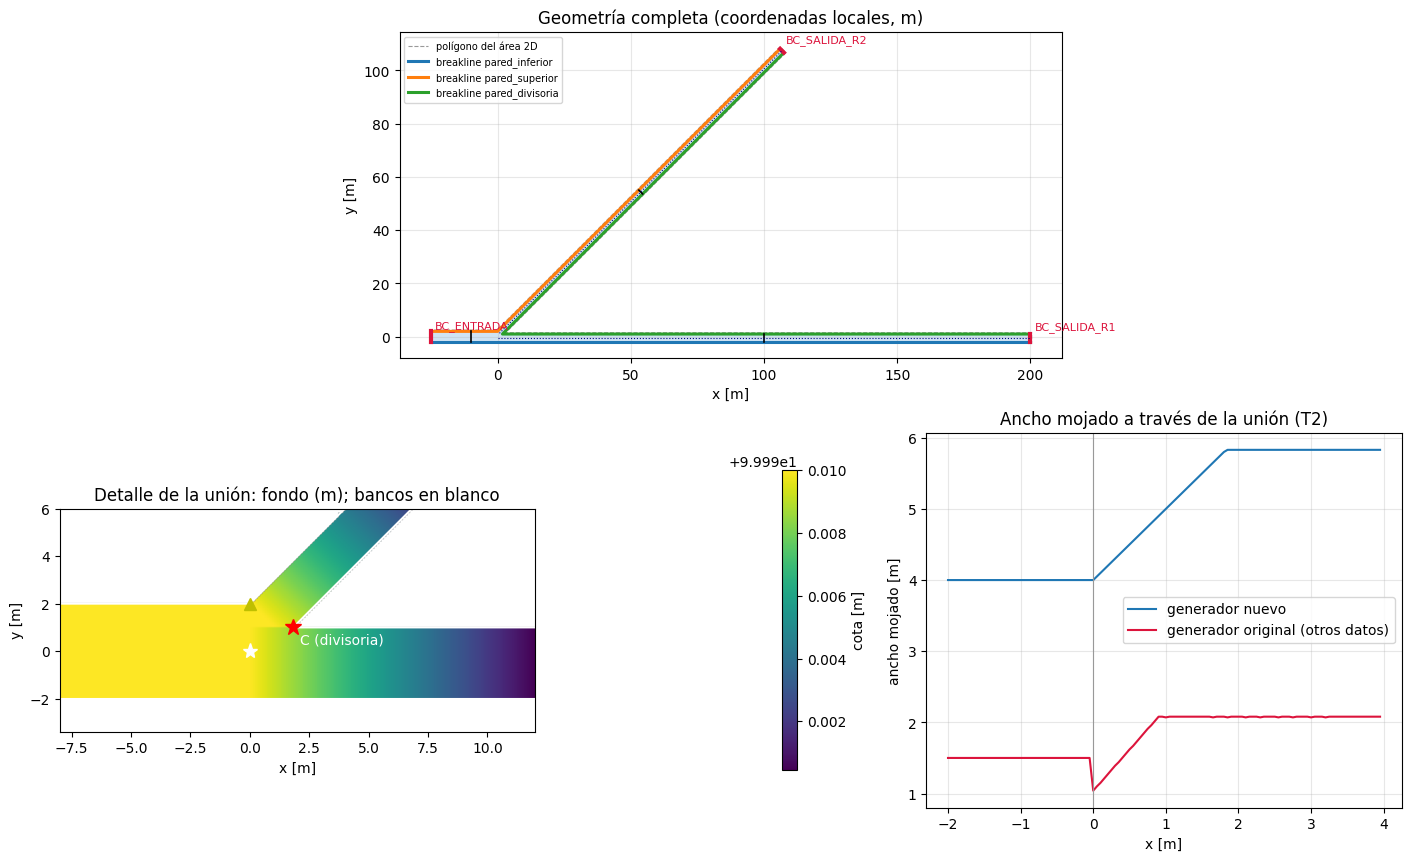

In [16]:
fig = plt.figure(figsize=(14, 8.5), layout="constrained")
gs = fig.add_gridspec(2, 2, height_ratios=[1.0, 1.15])
ax0 = fig.add_subplot(gs[0, :])
ax0.add_patch(plt.Polygon(np.array(vertices), closed=True, fc="#cfe3f3", ec="none"))
x_, y_ = area2d.exterior.xy; ax0.plot(x_, y_, color="0.6", lw=0.8, ls="--", label="polígono del área 2D")
for k, pts in breaklines.items():
    p = np.array(pts); ax0.plot(p[:, 0], p[:, 1], lw=2.2, label=f"breakline {k}")
for k, pts in bc_lineas.items():
    p = np.array(pts); ax0.plot(p[:, 0], p[:, 1], color="crimson", lw=3); ax0.annotate(k, p.mean(axis=0), fontsize=8, color="crimson", xytext=(3, 6), textcoords="offset points")
for k, pts in lineas_Q.items():
    p = np.array(pts); ax0.plot(p[:, 0], p[:, 1], color="k", lw=1.2)
for k, pts in perfiles.items():
    p = np.array(pts); ax0.plot(p[:, 0], p[:, 1], color="navy", lw=0.8, ls=":")
ax0.set_aspect("equal"); ax0.set_title("Geometría completa (coordenadas locales, m)"); ax0.set_xlabel("x [m]"); ax0.set_ylabel("y [m]")
ax0.legend(fontsize=7, loc="upper left"); ax0.grid(alpha=0.3)

ax1 = fig.add_subplot(gs[1, 0])
# zona de la union: recorte por coordenadas
i0, i1 = int(round((ymax - 6.0)/DX_RASTER)), int(round((ymax + 3.4)/DX_RASTER))
j0, j1 = int(round((-8.0 - xmin)/DX_RASTER)), int(round((12.0 - xmin)/DX_RASTER))
zz = np.where(Z[i0:i1, j0:j1] > Z_BANCO - 0.01, np.nan, Z[i0:i1, j0:j1])
im = ax1.imshow(zz, extent=[-8, 12, -3.4, 6.0], cmap="viridis", origin="upper")
for k, pts in breaklines.items():
    p = np.array(pts); ax1.plot(p[:, 0], p[:, 1], "w-", lw=1.5)
ax1.plot(*C, "r*", ms=12); ax1.annotate("C (divisoria)", C, xytext=(5, -12), textcoords="offset points", color="w")
ax1.plot(*E, "y^", ms=9); ax1.annotate("E (esquina aguas arriba)", E, xytext=(-90, 8), textcoords="offset points", color="w", fontsize=8)
ax1.plot(0, 0, "w*", ms=11)
ax1.set_aspect("equal")
ax1.set_xlim(-8, 12); ax1.set_ylim(-3.4, 6.0)
ax1.set_title("Detalle de la unión: fondo (m); bancos en blanco"); ax1.set_xlabel("x [m]"); ax1.set_ylabel("y [m]")
plt.colorbar(im, ax=ax1, label="cota [m]", shrink=0.8)

ax2 = fig.add_subplot(gs[1, 1])
ax2.plot(xs_t, W_nuevo, label="generador nuevo")
ax2.plot(xs_t, W_orig, label="generador original (otros datos)", color="crimson")
ax2.axvline(0, color="0.6", lw=0.8)
ax2.set_xlabel("x [m]"); ax2.set_ylabel("ancho mojado [m]"); ax2.set_title("Ancho mojado a través de la unión (T2)")
ax2.grid(alpha=0.3); ax2.legend()
plt.savefig("salida_2d/mapa_verificacion.png", dpi=130)
plt.show()

## 10. Mallas, paso de tiempo y archivos para el repositorio

In [17]:
c_onda = np.sqrt(g*max(yd1, yd2)); V_max = max(ref1d["V [m/s]"])
mallas = []
for dx in (0.50, 0.25, 0.125):
    ncel = area2d.area/dx**2
    dt1 = dx/(V_max + c_onda)
    mallas.append({"Malla [m]": dx, "Celdas en el cauce (aprox.)": area_cauce/dx**2, "Celdas en el área 2D (aprox.)": ncel,
                   "Celdas a lo ancho del ramal 2": b2/dx, "dt para Courant = 1 [s]": dt1, "dt para Courant = 3 [s]": 3*dt1})
display(pd.DataFrame(mallas).style.format({"Malla [m]": "{:.3f}", "Celdas en el cauce (aprox.)": "{:,.0f}", "Celdas en el área 2D (aprox.)": "{:,.0f}",
                                           "Celdas a lo ancho del ramal 2": "{:.0f}", "dt para Courant = 1 [s]": "{:.3f}", "dt para Courant = 3 [s]": "{:.3f}"}).hide(axis="index"))

resumen_json = {
    "origen_utm_ficticio": {"X": X0, "Y": Y0, "epsg": EPSG}, "theta_deg": THETA_DEG, "n_canal_a": N_CANAL_A,
    "ref_1d": {"Q1": Q1, "Q2": Q2, "HJ": HJ, "phi": Q2/datos["Q0"], "yJ": yJ, "Fr_canal_principal": float(ref1d.loc[0, "Froude"])},
    "ref_1d_perfil_integrado": {"Q1": Q1_int, "Q2": Q2_int, "HJ": H_int, "phi": phi_int},
    "bc": {"Q0": datos["Q0"], "WSE_salida_R1": WSE_C1, "WSE_salida_R2": WSE_C2, "t_rampa": T_RAMPA, "t_total": T_TOTAL, "Q_inicial": Q_INICIAL},
    "pruebas_cumplen": f"{int(tabla_pruebas['¿Cumple?'].sum())} de {len(tabla_pruebas)}"}
with open("salida_2d/datos_2d.json", "w", encoding="utf-8") as f:
    json.dump(resumen_json, f, indent=2)
archivos = sorted(os.listdir("salida_2d"))
print("Archivos generados en salida_2d/:")
for a in archivos: print(f"   {a:34s} {os.path.getsize('salida_2d/' + a)/1e3:10.1f} kB")

Malla [m],Celdas en el cauce (aprox.),Celdas en el área 2D (aprox.),Celdas a lo ancho del ramal 2,dt para Courant = 1 [s],dt para Courant = 3 [s]
0.500,"4,001","5,518",4,0.086,0.257
0.250,"16,005","22,071",8,0.043,0.128
0.125,"64,021","88,283",16,0.021,0.064


Archivos generados en salida_2d/:
   area_2d.dbf                               0.2 kB
   area_2d.prj                               0.4 kB
   area_2d.shp                               0.3 kB
   area_2d.shx                               0.1 kB
   bc_entrada_hydrograph.csv                 0.0 kB
   bc_lines.dbf                              0.1 kB
   bc_lines.prj                              0.4 kB
   bc_lines.shp                              0.4 kB
   bc_lines.shx                              0.1 kB
   bc_salida_stage.csv                       0.1 kB
   breaklines.dbf                            0.1 kB
   breaklines.prj                            0.4 kB
   breaklines.shp                            0.4 kB
   breaklines.shx                            0.1 kB
   datos_2d.json                             0.7 kB
   manning_regiones.dbf                      0.2 kB
   manning_regiones.prj                      0.4 kB
   manning_regiones.shp                      0.5 kB
   manning_regiones.shx       

## 11. Guía para montar el modelo en HEC-RAS 2D

1. **Proyección.** RAS Mapper → Set Projection → usar `salida_2d/terreno_partidor.prj` o el CRS UTM 18 S (EPSG:32718).
2. **Terreno.** Create New RAS Terrain con `terreno_partidor.tif`.
3. **Área 2D.** Importar `area_2d.shp` como polígono de área de flujo 2D. Las líneas `bc_lines.shp` coinciden con su borde.
4. **Breaklines.** Importar `breaklines.shp` y asignar el espaciado de celda a lo largo de ellas igual al tamaño de malla (paredes alineadas con las caras de celda).
5. **Mallas.** Tres planes con celdas de 0.50, 0.25 y 0.125 m (razón de refinamiento 2). Para $\varphi$ se calcula el índice de convergencia de malla (Roache) o la extrapolación de Richardson.
6. **Rugosidad.** Base n = 0.015; región `n_ramal2` con n = 0.018 (`manning_regiones.shp`).
7. **Bordes.** `BC_ENTRADA`: hidrograma de `bc_entrada_hydrograph.csv` (pendiente de energía para distribuir el caudal en la línea: ≈ la fricción del canal principal, del orden de 1e-3). `BC_SALIDA_R1` y `BC_SALIDA_R2`: nivel de agua constante, con los valores de `bc_salida_stage.csv`.
8. **Condición inicial.** Nivel de agua uniforme de 101.44 m.
9. **Tiempo.** Simulación de 3600 s; paso adaptativo con Courant máximo ≤ 1 a 3 según el solver (verificar en el manual de la versión que uses). Promediar el estado permanente en los últimos 600 s.
10. **Resultados a exportar.** Caudal en las tres líneas `Q_*` y nivel en los puntos de `puntos_observacion.shp`. Anotar el *Percent Volume Error* de cada malla. Perfiles de superficie libre a lo largo de `EJE_RAMAL1/2` para comparar con `perfil_1d_ramal1/2.csv`.
11. **Qué se compara.** $\varphi_{2D}=Q_{R2}/Q_0$ contra $\varphi_{1D}$: `ref_1d.phi` (Formulación II, un paso) y `ref_1d_perfil_integrado.phi` (perfil integrado). El balance $Q_{R1}+Q_{R2}-Q_0$ debe ser pequeño en cada malla.

**Lo que no verifiqué:** no ejecuté HEC-RAS. Los pasos 1 a 9 describen cómo usar los archivos; las opciones exactas de cada versión (importación de shapefiles, paso adaptativo, pendiente de energía de la BC) deben confirmarse en el programa.